# PDF 문서를 이용해서 RAG 서비스 구현 
- 규칙이 아닌 의미 기반 RAG 구현하기 

# Create VectorDB

## Loader
> 문서를 읽어서 Document 객체 생성

In [2]:
from langchain_pymupdf4llm import PyMuPDF4LLMLoader

file = "./data/Attention Is All You Need.pdf"
loader = PyMuPDF4LLMLoader(
    file_path=file, mode="page"
)

In [3]:
docs = loader.load()
len(docs)

Consider using the pymupdf_layout package for a greatly improved page layout analysis.


15

In [6]:
# 각 페이지의 텍스트 문장들을 하나의 문자열로 결합 
full_text = "\n\n".join(
    doc.page_content for doc in docs
)

len(full_text)

40991

In [8]:
print(full_text[:500])

Provided proper attribution is provided, Google hereby grants permission to
reproduce the tables and figures in this paper solely for use in journalistic or

scholarly works.

## **Attention Is All You Need**



**Niki Parmar** _[∗]_
Google Research
```
nikip@google.com

```


**Ashish Vaswani** _[∗]_

Google Brain
```
avaswani@google.com

```

**Llion Jones** _[∗]_
Google Research
```
 llion@google.com

```


**Noam Shazeer** _[∗]_

Google Brain
```
noam@google.com

```


**Jakob Uszkoreit** _[


## Split

### LLM Section 분석 

> 목차 내용에 맞게 문서를 자르자!!

In [11]:
from pydantic import BaseModel, Field 

class Section(BaseModel):
    title: str = Field(description="원본에 존재하는 섹션 제목")
    start_text: str = Field(description="해당 섹션의 시작 문자열")

class ListSection(BaseModel):
    sections: list[Section]

In [12]:
from langchain_core.output_parsers import PydanticOutputParser

output_parser = PydanticOutputParser(pydantic_object=ListSection)

In [14]:
format_instructions = output_parser.get_format_instructions()
print(format_instructions)

The output should be formatted as a JSON instance that conforms to the JSON schema below.

As an example, for the schema {"properties": {"foo": {"title": "Foo", "description": "a list of strings", "type": "array", "items": {"type": "string"}}}, "required": ["foo"]}
the object {"foo": ["bar", "baz"]} is a well-formatted instance of the schema. The object {"properties": {"foo": ["bar", "baz"]}} is not well-formatted.

Here is the output schema:
```
{"$defs": {"Section": {"properties": {"title": {"description": "원본에 존재하는 섹션 제목", "title": "Title", "type": "string"}, "start_text": {"description": "해당 섹션의 시작 문자열", "title": "Start Text", "type": "string"}}, "required": ["title", "start_text"], "title": "Section", "type": "object"}}, "properties": {"sections": {"items": {"$ref": "#/$defs/Section"}, "title": "Sections", "type": "array"}}, "required": ["sections"]}
```


In [15]:
from langchain_core.prompts import PromptTemplate

prompt = PromptTemplate(
    template="""다음 논문을 분석하여 Section별 제목과
시작 위치를 추출하세요.

반환 형식:
{format_instructions}

주의사항:
- 원문에 존재하는 제목만 반환하세요.
- start_text는 원본 문자열에 실제 존재해야 합니다.
- 목차가 아닌 본문 내 제목을 기준으로 하세요.

논문 내용:
{full_text}
""",
    input_variables=["full_text"],
    partial_variables={"format_instructions":format_instructions}
)

In [16]:
prompt

PromptTemplate(input_variables=['full_text'], input_types={}, partial_variables={'format_instructions': 'The output should be formatted as a JSON instance that conforms to the JSON schema below.\n\nAs an example, for the schema {"properties": {"foo": {"title": "Foo", "description": "a list of strings", "type": "array", "items": {"type": "string"}}}, "required": ["foo"]}\nthe object {"foo": ["bar", "baz"]} is a well-formatted instance of the schema. The object {"properties": {"foo": ["bar", "baz"]}} is not well-formatted.\n\nHere is the output schema:\n```\n{"$defs": {"Section": {"properties": {"title": {"description": "원본에 존재하는 섹션 제목", "title": "Title", "type": "string"}, "start_text": {"description": "해당 섹션의 시작 문자열", "title": "Start Text", "type": "string"}}, "required": ["title", "start_text"], "title": "Section", "type": "object"}}, "properties": {"sections": {"items": {"$ref": "#/$defs/Section"}, "title": "Sections", "type": "array"}}, "required": ["sections"]}\n```'}, template='다음

In [20]:
from langchain_openai import ChatOpenAI 

model = ChatOpenAI(
    model="gpt-6-luna"
)

In [21]:
chain = prompt | model | output_parser

In [22]:
results = chain.invoke({
    "full_text":full_text
})

In [44]:
len(results.sections) # LLM이 만든 전체 목차의 수 

26

In [47]:
results.sections[2].title, results.sections[2].start_text 

('2 Background', '**2** **Background**')

### Section Document 생성

In [ ]:
# 실제 본문에서 시작 위치 탐색
positions = []

for section in results.sections:
    # start: 해당 텍스트의 위치 정보
    start = full_text.find(section.start_text)

    if start == -1:
        raise ValueError(f"제목을 찾지 못했습니다: {section.title}")

    positions.append({
        "title": section.title,
        "start": start
    })

# 위치순 정렬
positions.sort(key=lambda x: x["start"])

In [65]:
from langchain_core.documents import Document

# Section별 Document 생성
section_docs = []

for i, section in enumerate(positions):
    start = section["start"]

    if i + 1 < len(positions):
        end = positions[i + 1]["start"]
    else: # 마지막 목차(section)
        end = len(full_text)

    section_docs.append(
        Document(
            page_content=full_text[start:end].strip(),
            metadata={
                "section": section["title"],
                "source":file
            }
        )
    )

In [66]:
len(section_docs) == len(results.sections)

True

In [67]:
print(f"제목: {section_docs[1].metadata['section']}")
print("="*50)
print(section_docs[1].page_content)

제목: 1 Introduction
**1** **Introduction**


Recurrent neural networks, long short-term memory [13] and gated recurrent [7] neural networks
in particular, have been firmly established as state of the art approaches in sequence modeling and
transduction problems such as language modeling and machine translation [35, 2, 5]. Numerous
efforts have since continued to push the boundaries of recurrent language models and encoder-decoder
architectures [38, 24, 15].


Recurrent models typically factor computation along the symbol positions of the input and output
sequences. Aligning the positions to steps in computation time, they generate a sequence of hidden
states _ht_, as a function of the previous hidden state _ht−_ 1 and the input for position _t_ . This inherently
sequential nature precludes parallelization within training examples, which becomes critical at longer
sequence lengths, as memory constraints limit batching across examples. Recent work has achieved
significant improvements in 

### RecursiveCharacterTextSplitter

> rule base(RecursiveCharacterTextSplitter)를 사용해서 문서를 자르자!!

In [68]:
# 하나의 문서 내용이 너무 크기 때문에 Split 필요
max(
    len(doc.page_content) for doc in section_docs
)

7840

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

# A/B 테스트를 통해 가장 성능이 좋은 chunk_size를 정의해야함!!!
splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000, # 최대 문서의 길이
    chunk_overlap=100, # 각 문서별 겹치는 글자의 길이 
    length_function=len
)

In [71]:
section_docs_by_splitter = splitter.split_documents(section_docs)

In [72]:
len(section_docs_by_splitter), len(section_docs)

(60, 26)

In [73]:
print(f"제목: {section_docs_by_splitter[1].metadata['section']}")
print("="*50)
print(section_docs_by_splitter[1].page_content)

제목: Abstract
The dominant sequence transduction models are based on complex recurrent or
convolutional neural networks that include an encoder and a decoder. The best
performing models also connect the encoder and decoder through an attention
mechanism. We propose a new simple network architecture, the Transformer,
based solely on attention mechanisms, dispensing with recurrence and convolutions
entirely. Experiments on two machine translation tasks show these models to
be superior in quality while being more parallelizable and requiring significantly
less time to train. Our model achieves 28.4 BLEU on the WMT 2014 Englishto-German translation task, improving over the existing best results, including
ensembles, by over 2 BLEU. On the WMT 2014 English-to-French translation task,
our model establishes a new single-model state-of-the-art BLEU score of 41.8 after
training for 3.5 days on eight GPUs, a small fraction of the training costs of the


## Embedding Model

In [74]:
from langchain_openai import OpenAIEmbeddings

embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")

In [75]:
msg = "안녕하세요."
vector = embedding_model.embed_query(msg)

In [76]:
print(f"vector: {len(vector)}")
print("="*50)
print(vector[:10])

vector: 1536
[-0.0012950897216796875, -0.052490234375, -0.0161285400390625, 0.01904296875, 0.03564453125, -0.034332275390625, -0.06805419921875, 0.030517578125, -0.0242767333984375, -0.0491943359375]


## Create VectorStore

### Qdrant 구축 및 접속 확인 

In [77]:
from qdrant_client import QdrantClient 

client = QdrantClient(host="localhost", port=6333)
print("접속 성공")

접속 성공


### VectorStore

In [82]:
from langchain_qdrant import QdrantVectorStore

vectorstore = QdrantVectorStore.from_documents(
    documents=section_docs_by_splitter,
    embedding=embedding_model,
    collection_name="pdf_attention",
    location="http://localhost:6333"
)

In [83]:
retriever = vectorstore.as_retriever(search_kwargs={"k":3})

In [84]:
search_docs = retriever.invoke("Recurrent neural networks")

In [85]:
search_docs[0]

Document(metadata={'section': '1 Introduction', 'source': './data/Attention Is All You Need.pdf', '_id': '68b5f8a5-d4f7-48f5-84e8-477eec1f27a1', '_collection_name': 'pdf_attention'}, page_content='**1** **Introduction**\n\n\nRecurrent neural networks, long short-term memory [13] and gated recurrent [7] neural networks\nin particular, have been firmly established as state of the art approaches in sequence modeling and\ntransduction problems such as language modeling and machine translation [35, 2, 5]. Numerous\nefforts have since continued to push the boundaries of recurrent language models and encoder-decoder\narchitectures [38, 24, 15].')

# Create RAG Service

## State

In [88]:
from langgraph.graph.message import add_messages
from typing import Annotated 
from typing_extensions import TypedDict

class State(TypedDict):
    messages: Annotated[list, add_messages]

## Nodes

### RAG를 호출하는 Tool 생성

In [124]:
from langchain_core.tools import tool 

@tool
def search_docs_from_vectorstore(query:str) -> str:
    """
    Attention Is All You Need 논문의 내용을 찾는 VectorStore
    - query: 사용자의 논문에 대한 질문 
    """

    # similarity_search_with_relevance_scores()
    # => [(doc, score), (doc, score)]
    search_docs = vectorstore.similarity_search_with_relevance_scores(query, k=5)
    docs = [
        doc for doc, score in search_docs if score > 0.6
    ]

    if len(docs) == 0:
        return "사용자의 질문에 해당하는 논문 내용이 없습니다."

    return "\n".join(doc.page_content for doc in docs)


In [125]:
result = search_docs_from_vectorstore.invoke("Recurrent neural networks")
print(result)

**1** **Introduction**


Recurrent neural networks, long short-term memory [13] and gated recurrent [7] neural networks
in particular, have been firmly established as state of the art approaches in sequence modeling and
transduction problems such as language modeling and machine translation [35, 2, 5]. Numerous
efforts have since continued to push the boundaries of recurrent language models and encoder-decoder
architectures [38, 24, 15].
[6] Francois Chollet. Xception: Deep learning with depthwise separable convolutions. _arXiv_

_[preprint arXiv:1610.02357](http://arxiv.org/abs/1610.02357)_, 2016.


[7] Junyoung Chung, Çaglar Gülçehre, Kyunghyun Cho, and Yoshua Bengio. Empirical evaluation

of gated recurrent neural networks on sequence modeling. _CoRR_, abs/1412.3555, 2014.


[8] Chris Dyer, Adhiguna Kuncoro, Miguel Ballesteros, and Noah A. Smith. Recurrent neural

network grammars. In _Proc. of NAACL_, 2016.


[9] Jonas Gehring, Michael Auli, David Grangier, Denis Yarats, and Yann N

In [139]:
result = search_docs_from_vectorstore.invoke("안녕하세요")
print(result)

사용자의 질문에 해당하는 논문 내용이 없습니다.


### LLM Node

In [140]:
tools = [search_docs_from_vectorstore]

In [141]:
for tool in tools:
    print("=" * 50)
    print(f"Tool 이름: {tool.name}")
    print(f"Tool 설명: {tool.description}")
    print(f"Tool 인풋 파라미터: {tool.args}")
    print(f"Tool return_direct: {tool.return_direct}")

Tool 이름: search_docs_from_vectorstore
Tool 설명: Attention Is All You Need 논문의 내용을 찾는 VectorStore
- query: 사용자의 논문에 대한 질문
Tool 인풋 파라미터: {'query': {'title': 'Query', 'type': 'string'}}
Tool return_direct: False


In [142]:
from langchain_openai import ChatOpenAI 

model = ChatOpenAI(
    model="gpt-5-nano"
)

model_with_tools = model.bind_tools(tools)

In [143]:
from langchain_core.messages import HumanMessage, SystemMessage

response = model_with_tools.invoke(
    [   SystemMessage(content="너는 사용자의 질문에 해당하는 tool을 사용하는 AI Agent야."),
        HumanMessage(content="Attention Is All You Need 논문에 있는 Background 내용 설명해줘.")]
)

In [144]:
response.tool_calls

[{'name': 'search_docs_from_vectorstore',
  'args': {'query': 'Attention Is All You Need Background'},
  'id': 'call_6Nl3ef9Aficy28WWdHOtSTXQ',
  'type': 'tool_call'}]

In [145]:
def llm_node(state:State) -> State:

    messages = [SystemMessage(content="""당신은 AI 비서입니다.
사용자의 요청이 Attention Is All You Need 논문과 관련이 있다면, 적절한 도구를 사용해 주세요.
만약, 도구가 필요없다면 일반적인 대화를 해주세요.""")]
    messages += state['messages']

    response = model_with_tools.invoke(messages)
    return {
        **state,
        'messages':[response]
    }

In [146]:
result = llm_node({
    "messages":"Attention Is All You Need 논문의 초록 알려줘."
})

In [147]:
result['messages'][-1].tool_calls

[{'name': 'search_docs_from_vectorstore',
  'args': {'query': 'Attention Is All You Need abstract'},
  'id': 'call_DLvfBkYjyVOfcQWnkxZ4R2dN',
  'type': 'tool_call'}]

### tool_node

In [148]:
from langchain_core.messages import ToolMessage

def tool_node(state:State) -> State:

    ai_response = state['messages'][-1]
    tool_messages = []
    for tool_call in ai_response.tool_calls:
        tool_name = tool_call['name']
        tool_args = tool_call['args']

        tool_fnc = next(tool for tool in tools if tool.name == tool_name)
        tool_result = tool_fnc.invoke(tool_args)
        tool_messages.append(
            ToolMessage(content=tool_result, tool_call_id=tool_call['id'])
        )

    return {
        **state,
        'messages':tool_messages
    }

In [149]:
tool_result = tool_node(result)

In [150]:
print(tool_result['messages'][-1].content)

**Abstract**
**3.2** **Attention**


An attention function can be described as mapping a query and a set of key-value pairs to an output,
where the query, keys, values, and output are all vectors. The output is computed as a weighted sum


3




Scaled Dot-Product Attention Multi-Head Attention


Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several
attention layers running in parallel.


of the values, where the weight assigned to each value is computed by a compatibility function of the
query with the corresponding key.
As side benefit, self-attention could yield more interpretable models. We inspect attention distributions
from our models and present and discuss examples in the appendix. Not only do individual attention
heads clearly learn to perform different tasks, many appear to exhibit behavior related to the syntactic
and semantic structure of the sentences.
**Attention Visualizations**


Figure 3: An example of the attention mechanism 

## Create Graph with Edge

In [151]:
def is_tools(state:State) -> str:
    ai_response = state['messages'][-1]

    if hasattr(ai_response, 'tool_calls') and ai_response.tool_calls:
        return "tool_node"

    return "end"

In [152]:
from langgraph.graph import StateGraph, START, END 
from langgraph.checkpoint.memory import MemorySaver

def create_graph(checkpointer=MemorySaver()):
    ###################################################
    # 그래프 객체 생성 
    ###################################################
    graph = StateGraph(State)

    ###################################################
    # 노드 추가  
    ###################################################
    graph.add_node("llm_node", llm_node)
    graph.add_node("tool_node", tool_node)

    ###################################################
    # 엣지 설정  
    ###################################################
    graph.add_edge(START, "llm_node")
    graph.add_conditional_edges(
        "llm_node", # 출발 노드 
        is_tools, # 조건 
        {
            "tool_node":"tool_node", # 도착 노드 
            "end":END # 도착 노드
        }
    )
    graph.add_edge("tool_node", "llm_node")

    ###################################################
    # compile with memory 
    ###################################################
    return graph.compile(checkpointer=checkpointer)


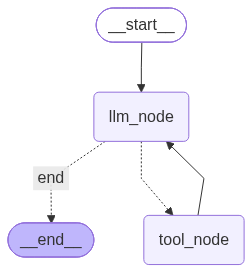

In [153]:
from IPython.display import Image, display

try:

    rag_with_memory = create_graph()
    
    display(
        Image(
            rag_with_memory.get_graph().draw_mermaid_png()
        )
    )
except Exception as e:
    print(f"그래프 표시 오류: {e}")

## Test

In [154]:
import uuid

# memory_id -> 각 대화별 식별을 할 수 있는 유닉크한 아이디 생성 
memory_id = str(uuid.uuid4())

print(f"유닉크한 아이디 생성: {memory_id}")

유닉크한 아이디 생성: 8527a041-e673-4d10-ba1d-b2704ba040cb


In [155]:
from langchain_core.messages import HumanMessage

# 중요: thread_id -> MemorySaver에서 대화별 아이디 
# 즉 thread_id를 통해서 대화별 내용을 조회/저장 간능 
# MemoryServer가 적용된 경우에는 thread_id는 필수!!!
config = {"configurable": {"thread_id": memory_id}}

print("=== Memory가 적용된 챗봇 테스트 ===")
print(f"config: {config}")

=== Memory가 적용된 챗봇 테스트 ===
config: {'configurable': {'thread_id': '8527a041-e673-4d10-ba1d-b2704ba040cb'}}


In [156]:
result = rag_with_memory.invoke(
    {"messages": [HumanMessage(content="Attention Is All You Need 논문의 초록 요약해서 알려줘.")]}, 
    # 여기가 중요!
    # 정의된 thread_id를 기준으로 대화 이력 데이터를 메모리에 저장
    config=config  
)


In [157]:
print(f"AI: {result['messages'][-1].content}")

AI: 다음은 Attention Is All You Need 논문의 초록 내용에 기반한 요약입니다.

- 핵심 아이디어: 질의(query)와 키-값 쌍의 집합을 입력으로 받아 출력을 생성하는 어텐션 함수의 정의를 제시합니다.

- 주요 특징: self-attention의 도입으로, 입력 간의 관계를 가중합으로 반영하여 정보를 처리하는 구조를 제안합니다. 어텐션의 시각화 및 해석 가능성도 강조합니다.

- 멀티-헤드 어텐션: 질의, 키, 값을 각각 여러 선형 변환으로 투영한 뒤, 각 투영 버전에서 어텐션을 병렬로 수행하고 결과를 합쳐 최종 출력을 얻는 방식으로 구성됩니다. 이로써 다양한 관점에서 정보를 취합합니다.

- 해석 가능성: 어텐션 헤드들이 서로 다른 작업을 학습하는 경향이 있으며, 문장의 구문적/의미적 구조를 포착하는 모습이 관찰됩니다.

요약하면, 이 논문은 어텐션에 기반한 신경망 아키텍처를 제시하고, 특히 멀티-헤드 어텐션과 어텐션 분포의 해석 가능성에 주목합니다.
